# 01 - Data exploration: CVRPLIB instances

**Goal of this notebook:** describe the data used to instantiate the CVRP model (report Section 2).
The data is *not* used for training anything. It only provides

* customer locations -> travel cost matrix $c_{ij}$
* customer demands $q_i$, vehicle capacity $Q$ and fleet size $K$
* a published best-known (here: proven optimal) cost, used later to measure the **gap** of each method.

Source: CVRPLIB, https://galgos.inf.puc-rio.br/cvrplib/ (see `data/README.md` for citations).

In [1]:
import sys
from math import lgamma, log
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.checker import check_solution
from src.data_loader import instance_table, load_bks, load_instance

FIG_DIR = ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Instance summary

*Tightness* = total demand / (vehicles x capacity). Values close to 1 mean the trucks are almost full,
which makes the capacity constraint harder to satisfy.
For the X set the fleet is unlimited, so tightness uses the minimum possible number of vehicles $\lceil \sum q_i / Q \rceil$.

In [2]:
rows = []
for row in instance_table():
    inst = load_instance(row["name"])
    routes, bks = load_bks(row["name"])
    check = check_solution(inst, routes, claimed_cost=bks)
    vehicles = inst.max_vehicles or inst.min_vehicles
    rows.append({
        "instance": inst.name,
        "tier": row["tier"],
        "customers n": inst.n_customers,
        "vehicles K": inst.max_vehicles if inst.max_vehicles else "unlimited",
        "capacity Q": inst.capacity,
        "total demand": int(inst.demand.sum()),
        "tightness": round(inst.demand.sum() / (vehicles * inst.capacity), 2),
        "best-known cost": bks,
        "proven optimal": row["bks_proven_optimal"],
        "BKS passes checker": check.feasible,
    })
summary = pd.DataFrame(rows)
summary

,instance,tier,customers n,vehicles K,capacity Q,total demand,tightness,best-known cost,proven optimal,BKS passes checker
0,P-n16-k8,small,15,8,35,246,0.88,450,yes,True
1,P-n19-k2,small,18,2,160,310,0.97,212,yes,True
2,P-n20-k2,small,19,2,160,310,0.97,216,yes,True
3,P-n22-k2,small,21,2,160,308,0.96,216,yes,True
4,E-n22-k4,small,21,4,6000,22500,0.94,375,yes,True
5,P-n23-k8,small,22,8,40,313,0.98,529,yes,True
6,B-n31-k5,medium,30,5,100,412,0.82,672,yes,True
7,A-n32-k5,medium,31,5,100,410,0.82,784,yes,True
8,A-n37-k5,medium,36,5,100,407,0.81,669,yes,True
9,P-n40-k5,medium,39,5,140,618,0.88,458,yes,True


Every published solution passes our independent checker **and** reproduces the published cost exactly.
This confirms that the distance convention (TSPLIB rounding of Euclidean distances) is the same as CVRPLIB's,
so the gaps we report later are comparable with the literature.

## 2. Why exact methods stop scaling (NP-hardness in numbers)

Even ignoring capacities, the number of ways to order the $n$ customers is $n!$.
The table shows $\log_{10}(n!)$, i.e. how many digits that number has.

In [3]:
growth = summary[["instance", "tier", "customers n"]].copy()
growth["digits in n!"] = [round(lgamma(n + 1) / log(10)) for n in growth["customers n"]]
growth

,instance,tier,customers n,digits in n!
0,P-n16-k8,small,15,12
1,P-n19-k2,small,18,16
2,P-n20-k2,small,19,17
3,P-n22-k2,small,21,20
4,E-n22-k4,small,21,20
5,P-n23-k8,small,22,21
6,B-n31-k5,medium,30,32
7,A-n32-k5,medium,31,34
8,A-n37-k5,medium,36,42
9,P-n40-k5,medium,39,46


## 3. What the instances look like

Depot = red square, customers = dots sized by demand. One instance from each tier.

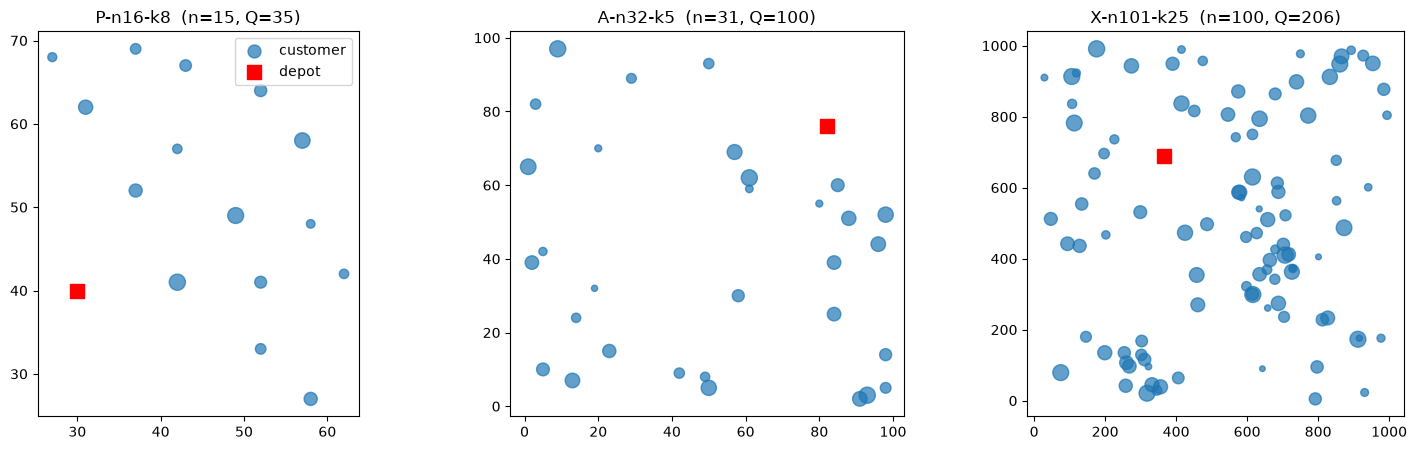

In [4]:
examples = ["P-n16-k8", "A-n32-k5", "X-n101-k25"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, name in zip(axes, examples):
    inst = load_instance(name)
    xy = inst.coords
    ax.scatter(xy[1:, 0], xy[1:, 1], s=15 + 120 * inst.demand[1:] / inst.demand.max(), alpha=0.7, label="customer")
    ax.scatter(*xy[0], marker="s", s=90, color="red", label="depot")
    ax.set_title(f"{name}  (n={inst.n_customers}, Q={inst.capacity})")
    ax.set_aspect("equal")
axes[0].legend(loc="best")
fig.tight_layout()
fig.savefig(FIG_DIR / "instances_overview.png", dpi=150)
plt.show()

## 4. A published optimal solution

The optimal routes of `A-n32-k5` (cost 784), drawn after they passed `check_solution`.
Our two methods will produce plots like this one, so we can compare them visually with the optimum.

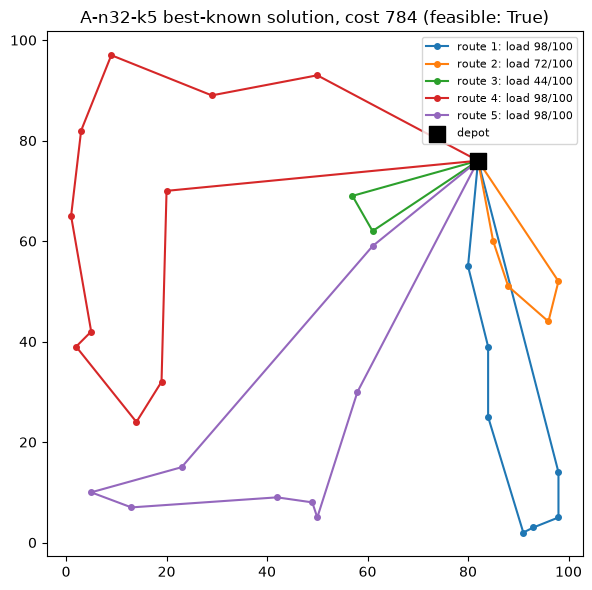

In [5]:
name = "A-n32-k5"
inst = load_instance(name)
routes, bks = load_bks(name)
check = check_solution(inst, routes, claimed_cost=bks)

fig, ax = plt.subplots(figsize=(6.5, 6))
for k, route in enumerate(routes):
    path = [0, *route, 0]
    ax.plot(inst.coords[path, 0], inst.coords[path, 1], "-o", ms=4, label=f"route {k + 1}: load {check.loads[k]}/{inst.capacity}")
ax.scatter(*inst.coords[0], marker="s", s=120, color="black", zorder=3, label="depot")
ax.set_title(f"{name} best-known solution, cost {check.cost} (feasible: {check.feasible})")
ax.set_aspect("equal")
ax.legend(fontsize=8, loc="best")
fig.tight_layout()
fig.savefig(FIG_DIR / "A-n32-k5_bks_routes.png", dpi=150)
plt.show()

## 5. Demand distribution

Demands differ a lot between instance families, which changes how many customers fit in one truck.

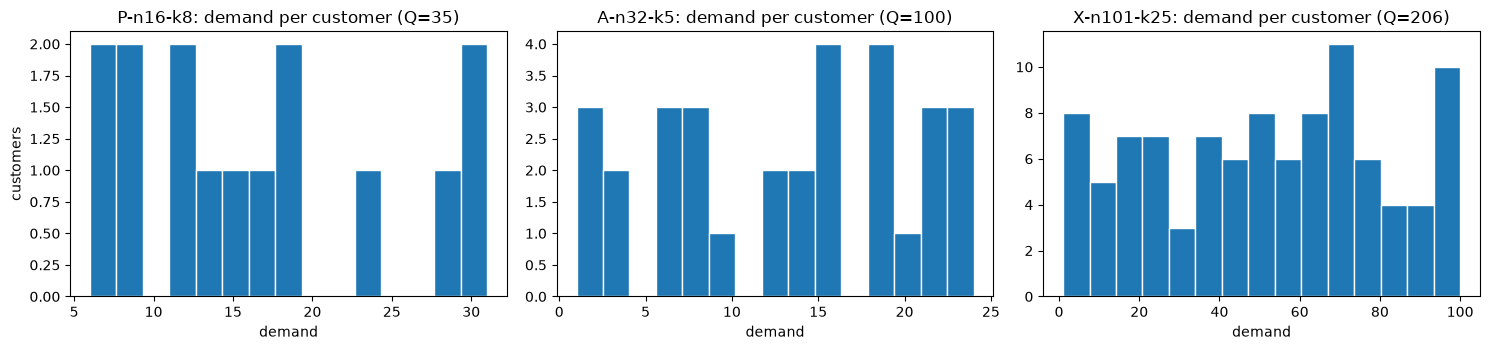

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, name in zip(axes, examples):
    inst = load_instance(name)
    ax.hist(inst.demand[1:], bins=15, edgecolor="white")
    ax.set_title(f"{name}: demand per customer (Q={inst.capacity})")
    ax.set_xlabel("demand")
axes[0].set_ylabel("customers")
fig.tight_layout()
fig.savefig(FIG_DIR / "demand_histograms.png", dpi=150)
plt.show()